# Basic Computer Vision Hands-on with OpenCV

This notebook introduces a few simple image-processing operations with OpenCV


## 00: Import libraries  

`cv2`: OpenCV, handles image I/O, low-level pixel operations and classical CV algorithms;  
`numpy`: array and numerical fundation for Python scientific libraries;  
`matplotlib`: general-purpose plotting library

In [2]:
# Import the required libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

ModuleNotFoundError: No module named 'cv2'

## 1. Load and display the image

OpenCV loads color images in **BGR** order by default.  
For visualization with Matplotlib, we convert the image to **RGB**.


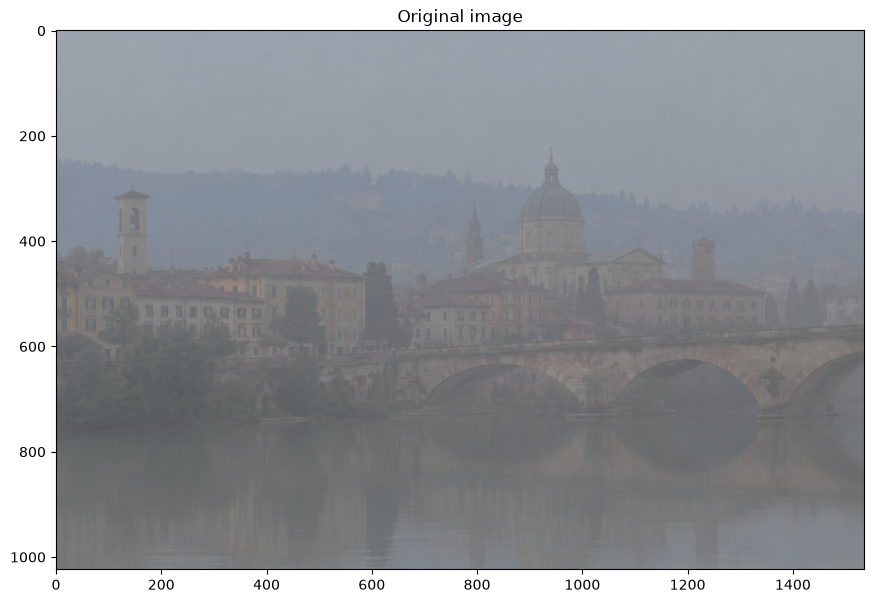

In [ ]:
# Set the image path
image_path = "../data/Lab00/Image02.png"

# Load the image with OpenCV
image_bgr = cv2.imread(image_path)

# Check that the image was loaded correctly
if image_bgr is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

# Convert BGR to RGB
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

# Display the image
plt.figure(figsize=(12, 7))
plt.imshow(image_rgb)
# plt.axis("off")
plt.title("Original image")
plt.show()


## 2. Extract the R, G, B channels

`cv2.imread(image_path)` returns a 3D-array (height, width, color)

In [8]:
# Extract the three channels from the RGB image
R = image_rgb[:, :, 0]
G = image_rgb[:, :, 1]
B = image_rgb[:, :, 2]

print("Image shape:", image_rgb.shape)
print("Red channel shape:", R.shape)
print("Green channel shape:", G.shape)
print("Blue channel shape:", B.shape)


Image shape: (1024, 1536, 3)
Red channel shape: (1024, 1536)
Green channel shape: (1024, 1536)
Blue channel shape: (1024, 1536)


## 3. Display the three channels separately

Each channel is shown as a grayscale image: brighter pixels correspond to larger values in that channel.

R, G and B are 2D-arrays of values [0, 255].

Without `cmap="grey"` the function `plt.imshow` uses default colormap blue-to-yellow, but applied to a 2D-array, leading to a misintepretation.

`vmin=0, vmax=255` fixes the colormap's normalization range explicitly; without this, matplotlib auto-scales such that black is the lowest value for the particular channel: this fix allow us to use the same normalization for each channel (the uint8 standard [0, 255], range on 8 bits).


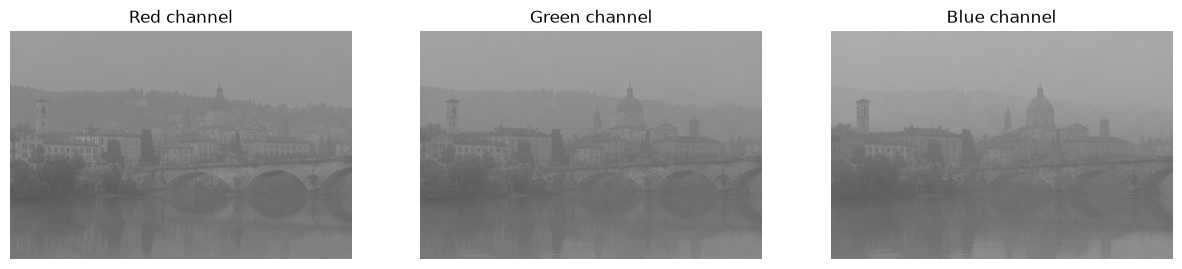

In [9]:
# Display the three channels separately
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(R, cmap="gray", vmin=0, vmax=255)
plt.title("Red channel")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(G, cmap="gray", vmin=0, vmax=255)
plt.title("Green channel")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(B, cmap="gray", vmin=0, vmax=255)
plt.title("Blue channel")
plt.axis("off")

plt.show()


## 4. Compute the RGB histograms

The same axis limits are used for all three histograms so that they can be compared directly.

`plt.plot(...)` draws the histogram as a continuous line curve, while `plt.bar(...)` do it as descrete bars.

`.ravel()` flattens a 2D-array into a 1D-array (row major logic) because `np.histogram(...)` needs a 1D sequence of values.

`np.histogram(data_1D, n_bins, range=(0, 256))`:
- divides the range [0,255] into n_bins equal-width bins and counts how many values from data_1D falls in each bean;
- returns the count (vector of n_bins values) and the bin edges.

With `n_bins = 256` the width of each bin (0-255) is exactly 1 is obtained the exact count for intensity value (i.e. maximum resolution): for n_bins < 256 spans multiple intensity values lumped together --> explain tradeoff between bins and resolution.

`n_bins = 256` + `range(0, 256)` --> bin_width = 256/256 = 1, edges = [0, 1, 2, ..., 255, 256] 
- bin 0 convers intensity values in range [0, 1) 
- bin 1 convers intensity values in range [1, 2)
- ...
- bin 255 convers intensity values in range [255, 256)

`n_bins = 32` + `range(0, 256)` --> bin_width = 256/32 = 8, edges = [0, 8, 16, ..., 248, 256] 
- bin 0 convers intensity values in range [0, 8) 
- bin 1 convers intensity values in range [8, 16)
- ...
- bin 255 convers intensity values in range [248, 256)
So there is not only one intensity value corespondig to a certain bin and the count (height of the histogram) is relate to all the initensity values considered!

`n_bins = 512` + `range(0, 256)` --> bin_width = 256/512 = 0.5, edges = [0, 0.5, 1, ..., 255.5, 256] 
- bin 0 convers intensity values in range [0, 0.5) 
- bin 1 convers intensity values in range [0.5, 1)
- ...
- bin 255 convers intensity values in range [255.5, 256)
Since we have only integers values, there is an alternance of count != 0 (e.g., bin 0) and count = 0 (e.g., bin 1).

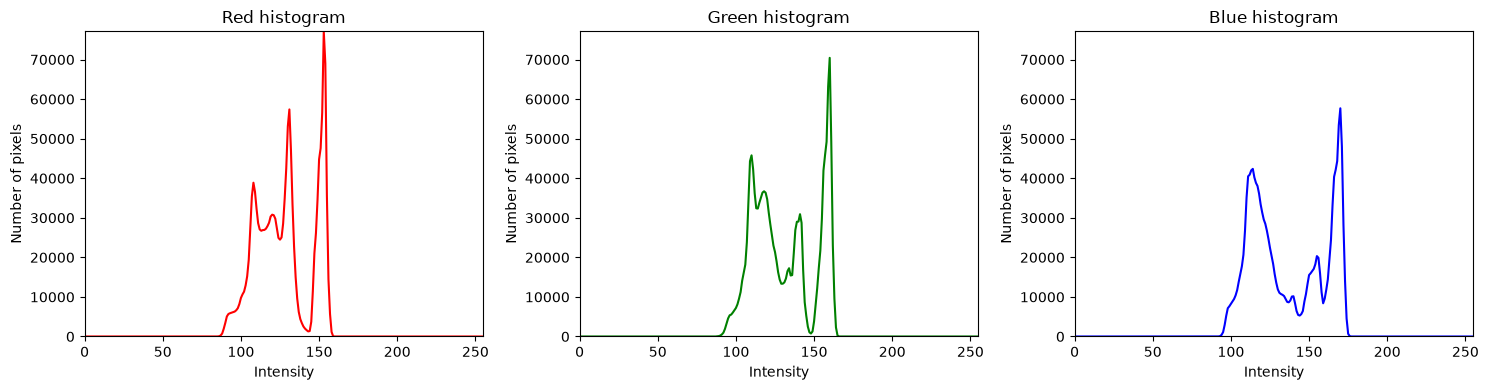

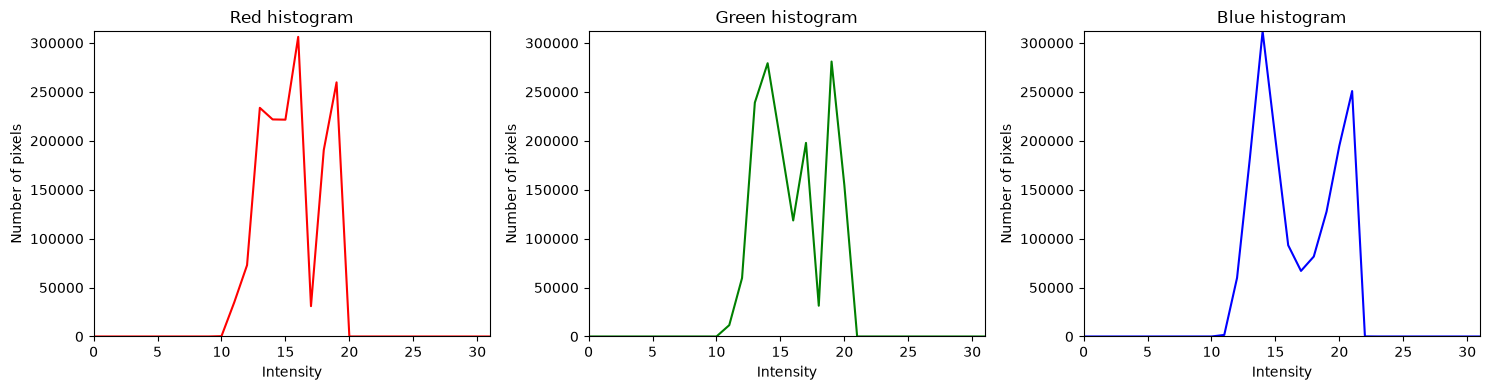

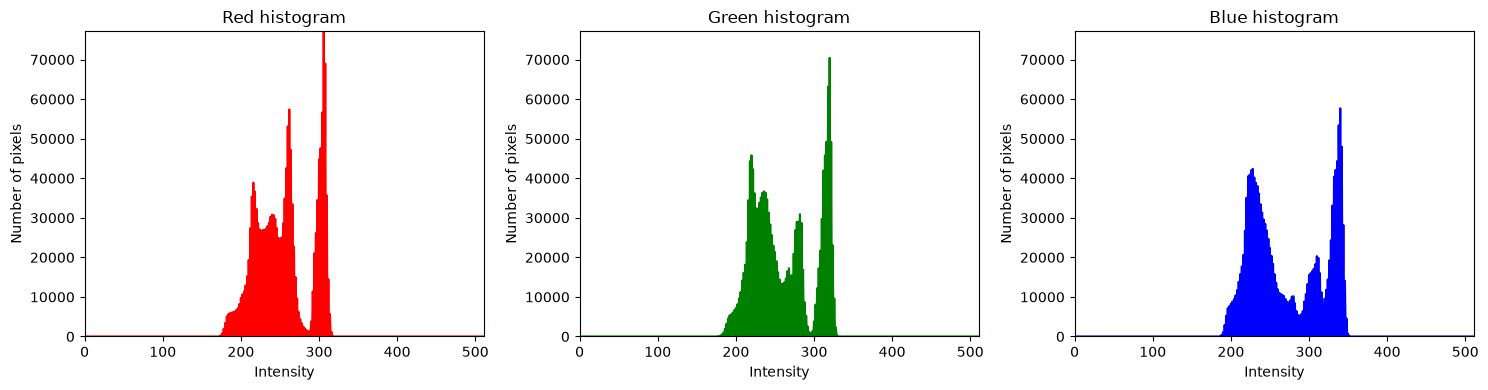

In [ ]:
# Compute histograms with a fixed number of bins
def compute_histogram(hist_R, hist_G, hist_B, n_bins):
    # Use the same y-axis limit for all channels
    y_max = max(hist_R.max(), hist_G.max(), hist_B.max())

    plt.figure(figsize=(15, 4))

    plt.subplot(1, 3, 1)
    plt.plot(hist_R, color="red")
    plt.xlim(0, n_bins-1)
    plt.ylim(0, y_max)
    plt.title("Red histogram")
    plt.xlabel("Intensity")
    plt.ylabel("Number of pixels")

    plt.subplot(1, 3, 2)
    plt.plot(hist_G, color="green")
    plt.xlim(0, n_bins-1)
    plt.ylim(0, y_max)
    plt.title("Green histogram")
    plt.xlabel("Intensity")
    plt.ylabel("Number of pixels")

    plt.subplot(1, 3, 3)
    plt.plot(hist_B, color="blue")
    plt.xlim(0, n_bins-1)
    plt.ylim(0, y_max)
    plt.title("Blue histogram")
    plt.xlabel("Intensity")
    plt.ylabel("Number of pixels")

    plt.tight_layout()
    plt.show();

n_bins = 256
hist_R, _ = np.histogram(R.ravel(), n_bins, range=(0, 256))
hist_G, _ = np.histogram(G.ravel(), n_bins, range=(0, 256))
hist_B, _ = np.histogram(B.ravel(), n_bins, range=(0, 256))
compute_histogram(hist_R, hist_G, hist_B, n_bins)

n_bins = 32
hist_R, _ = np.histogram(R.ravel(), n_bins, range=(0, 256))
hist_G, _ = np.histogram(G.ravel(), n_bins, range=(0, 256))
hist_B, _ = np.histogram(B.ravel(), n_bins, range=(0, 256))
compute_histogram(hist_R, hist_G, hist_B, n_bins)

n_bins = 512
hist_R, _ = np.histogram(R.ravel(), n_bins, range=(0, 256))
hist_G, _ = np.histogram(G.ravel(), n_bins, range=(0, 256))
hist_B, _ = np.histogram(B.ravel(), n_bins, range=(0, 256))
compute_histogram(hist_R, hist_G, hist_B, n_bins)


## 5. Three simple histogram-based image manipulations

We consider three basic examples:

1. **Brightness increase**: shift all intensities toward larger values.
2. **Contrast stretching**: expand the intensity range.
3. **Histogram equalization**: redistribute intensities to increase contrast.

These operations are useful for understanding how changes in the histogram affect the image.

**Brightness increase**  
- `astype(type)` is a method which casts all the elements in a vector to type;  
In this case is essential: if I add M to the intensity of white pixel (255) on 8 bit (0-255) I obtain a dark pixel due to overflow in binary system (254 -> 255 -> 0 -> 1 -> 2 ...) of value 0+M, instaed of one brighter. Therefore, is necessary to cast to 16bit integers;  
- `np.clip(..., 0, 255)` allow to apply saturation to the correct computed intensity values;  
- Effect on the histogram: shift of M bins for each count (or less if saturated).  

**Contrast stretching**
- min/max are called on the hole image: it is considered the highest or the lowest value across the three channels;
- `(img_float - min_val) / (max_val - min_val)` is a normalization in range [0,1] (value = min_val --> 0, value = max_val --> 1);
- `contrast = (255 * contrast).astype(np.uint8)` rescale and convert to integer;
- Effect on the histogram: same shape of the original but stretched horizontally to span the full range [0,255].

**Histogram equalization**
- `cv2.equalizeHist` accepts a single-channel (2D-array) 8-bit image and equilize the intensity distribution using the cumulative distribution function as a the pixel-remapping function.

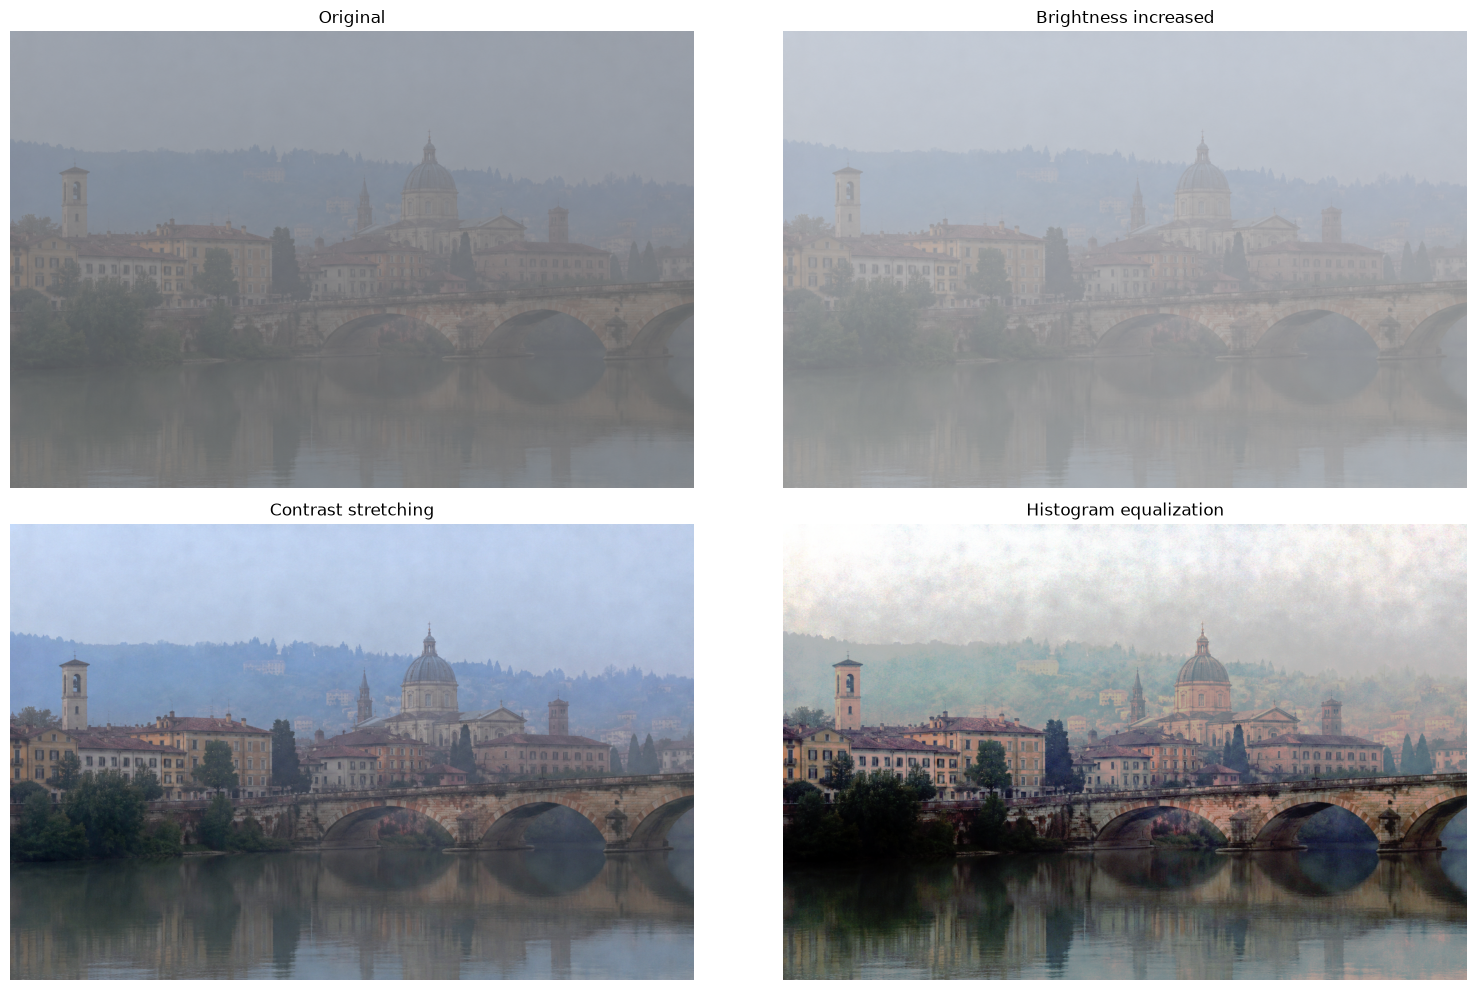

In [11]:
# 1. Increase brightness
M = 40
bright = np.clip(image_rgb.astype(np.int16) + M, 0, 255).astype(np.uint8)

# 2. Contrast stretching
img_float = image_rgb.astype(np.float32)
min_val = img_float.min()
max_val = img_float.max()
contrast = (img_float - min_val) / (max_val - min_val)
contrast = (255 * contrast).astype(np.uint8)

# 3. Histogram equalization applied independently to the three channels
equalized = np.zeros_like(image_rgb)
for color in range(3):
    equalized[:, :, color] = cv2.equalizeHist(image_rgb[:, :, color])

# Display the results
plt.figure(figsize=(16, 10))

plt.subplot(2, 2, 1)
plt.imshow(image_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(bright)
plt.title("Brightness increased")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(contrast)
plt.title("Contrast stretching")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(equalized)
plt.title("Histogram equalization")
plt.axis("off")

plt.tight_layout()
plt.show()


### Compare the histograms after manipulation


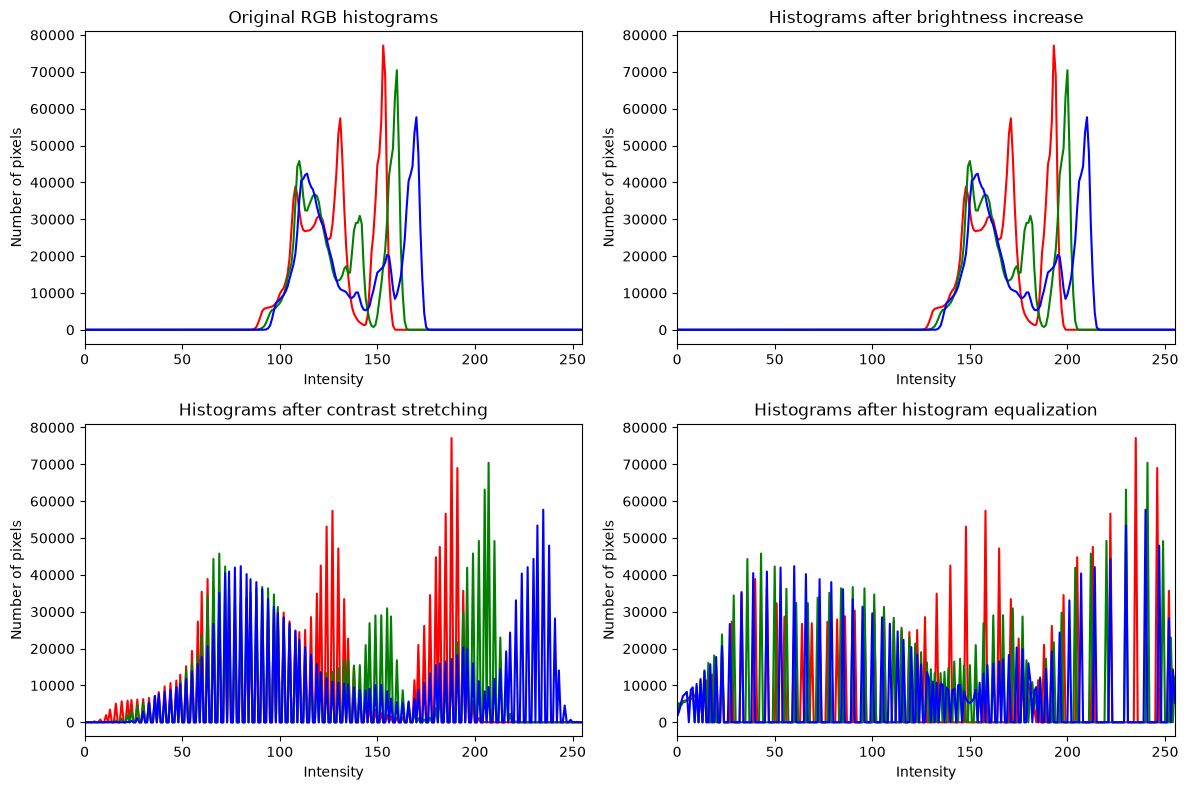

In [12]:
# Helper function to plot RGB histograms
def plot_rgb_histograms(img, title, ax):
    colors = ["red", "green", "blue"]

    for c, color in enumerate(colors):
        hist, _ = np.histogram(
            img[:, :, c].ravel(),
            bins=256,
            range=(0, 256)
        )
        ax.plot(hist, color=color)

    ax.set_xlim(0, 255)
    ax.set_xlabel("Intensity")
    ax.set_ylabel("Number of pixels")
    ax.set_title(title)


# Create a 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

plot_rgb_histograms(
    image_rgb,
    "Original RGB histograms",
    axes[0, 0]
)

plot_rgb_histograms(
    bright,
    "Histograms after brightness increase",
    axes[0, 1]
)

plot_rgb_histograms(
    contrast,
    "Histograms after contrast stretching",
    axes[1, 0]
)

plot_rgb_histograms(
    equalized,
    "Histograms after histogram equalization",
    axes[1, 1]
)

plt.tight_layout()
plt.show()


## 6. Crop a small patch from the image

Choose a small rectangular region containing a distinctive object, for example one of the buildings in the background.

The coordinates below are only an example and can be modified interactively.


In [13]:
# Select a point with the mouse using OpenCV

selected_point = (350, 450)

"""
def select_point(event, x, y, flags, param):
    global selected_point

    if event == cv2.EVENT_LBUTTONDOWN:
        selected_point = (x, y)
        print("Selected point:", selected_point)


# Open a window containing the image
cv2.namedWindow("Select patch center")
cv2.setMouseCallback("Select patch center", select_point)

# get the point with matplotlib
plt.figure(figsize=(12, 7))
plt.imshow(image_rgb)
plt.title("Click to select the patch center")
pts = plt.ginput(1)  # click once in the figure; blocks until you do
selected_point = (int(pts[0][0]), int(pts[0][1]))
plt.close()

# Wait for a key (selected point)
cv2.waitKey(0)
cv2.destroyAllWindows()
"""

'\ndef select_point(event, x, y, flags, param):\n    global selected_point\n\n    if event == cv2.EVENT_LBUTTONDOWN:\n        selected_point = (x, y)\n        print("Selected point:", selected_point)\n\n\n# Open a window containing the image\ncv2.namedWindow("Select patch center")\ncv2.setMouseCallback("Select patch center", select_point)\n\n# get the point with matplotlib\nplt.figure(figsize=(12, 7))\nplt.imshow(image_rgb)\nplt.title("Click to select the patch center")\npts = plt.ginput(1)  # click once in the figure; blocks until you do\nselected_point = (int(pts[0][0]), int(pts[0][1]))\nplt.close()\n\n# Wait for a key (selected point)\ncv2.waitKey(0)\ncv2.destroyAllWindows()\n'

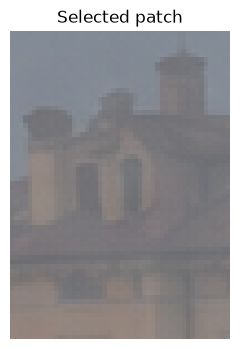

In [19]:
# Get the selected coordinates
x_center = selected_point[0]
y_center = selected_point[1]

# Define the patch size
patch_w = 50
patch_h = 70

# Compute the patch boundaries
x1 = x_center - patch_w // 2
x2 = x_center + patch_w // 2
y1 = y_center - patch_h // 2
y2 = y_center + patch_h // 2

# Crop the patch
patch = image_rgb[y1:y2, x1:x2]

# Display the patch
plt.figure(figsize=(4, 4))
plt.imshow(patch)
plt.title("Selected patch")
plt.axis("off")
plt.show()

## 7. Brute-force pattern matching

We slide the patch over the full image.

For every possible position, we compute the Euclidean distance between the patch and the corresponding region of the image.

A small Euclidean distance means that the two regions are similar.

We convert the distance into a similarity using:

$$
s = e^{-\frac{d}{\sigma}}
$$

where $d$ is the Euclidean distance and $\sigma$ controls how quickly the similarity decreases.

For efficiency, the image and the patch are converted to grayscale before the brute-force search.

similarity_map is build such that similarity_map[i,j] coresponds to the similarity values obtained comparing the patch to the current patch in position (y=i,x=j).


In [37]:
# Convert image and patch to grayscale
gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)
patch_gray = cv2.cvtColor(patch, cv2.COLOR_RGB2GRAY)

# Convert to float to avoid integer overflow
gray = gray.astype(np.float32)
patch_gray = patch_gray.astype(np.float32)

# 2 outputs since image and patch are in gray scale, i.e. 2D-arrays
patch_h, patch_w = patch_gray.shape
image_h, image_w = gray.shape

# The similarity map contains one value for every valid patch position
similarity_map = np.zeros(
    (image_h - patch_h + 1, image_w - patch_w + 1),
    dtype=np.float32
)

# Scale parameter used in the exponential
sigma = 5000.0

# Brute-force search
best_y = 0
best_x = 0
best_similarity = 0
for y in range(image_h - patch_h + 1):
    for x in range(image_w - patch_w + 1):

        # Extract the region currently compared with the patch
        current_region = gray[y:y + patch_h, x:x + patch_w]

        # Compute the Euclidean distance
        distance = np.linalg.norm(current_region - patch_gray)

        # Convert distance into similarity
        similarity = np.exp(-distance / sigma)

        # Store the result
        similarity_map[y, x] = similarity

        # check for best match
        if similarity > best_similarity:
            best_similarity = similarity
            best_y = y
            best_x = x

print("Similarity map shape:", similarity_map.shape)


Similarity map shape: (955, 1487)


## 8. Visualize the similarity map superimposed to the original image (in greyscale)

**Goal**  
Draw the full original image as a backdrop, then paint the (smaller) similarity_map on top as a semi-transparent color-coded heatmap, correctly aligned to the region of the image it actually corresponds to.

**Note about `extent=[left, right, bottom, top]` parameter**  
`plt.imshow` stretches whatever array you give it to fill the entire current axes, i.e., without extent the smaller image would be stretched.
I want the result of the similarity computation of similarity_map[i,j] to be diaplayed exactly on the center of the patch which top-left corner is in position (i,j), i.e., the similarity says how well a full `patch_w x patch_h` region centered in that position match the chosen template.

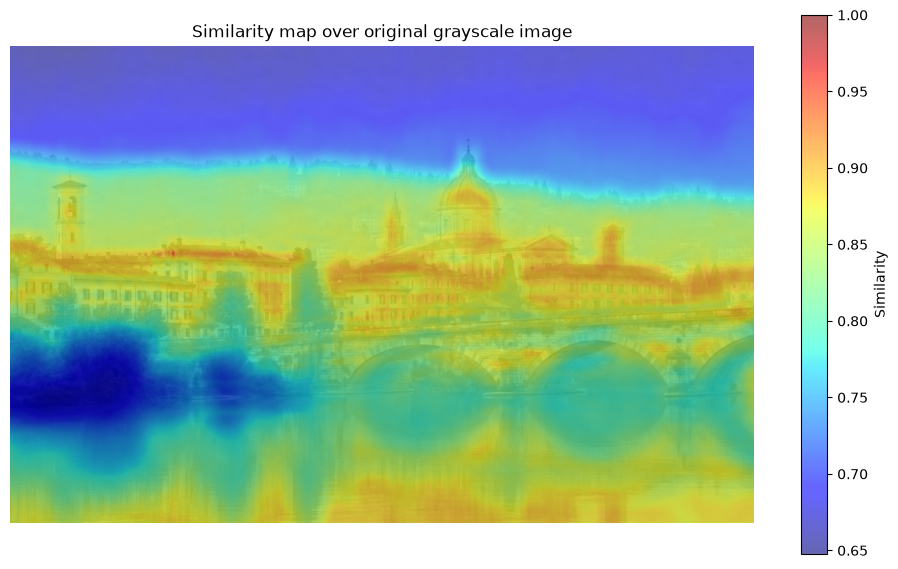

In [38]:
# Recompute gray-scale image since section 7 rewrote it
gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)

half_w = patch_w // 2
half_h = patch_h // 2

plt.figure(figsize=(12, 7))

# Full original grayscale image
plt.imshow(gray, cmap="gray")

# Overlay similarity map only in the valid internal region
plt.imshow(
    similarity_map,
    cmap="jet", # rainbow-style colormap: blue = low value, green/yellow = mid-range value, red = high value
    alpha=0.6,  # overlay opacity to a certain percentage 1-alpha*100 % still shows through the color 
    extent=[
        half_w,
        half_w + similarity_map.shape[1],
        half_h + similarity_map.shape[0],
        half_h
    ] # type: ignore
)

plt.colorbar(label="Similarity")
plt.axis("off")
plt.title("Similarity map over original grayscale image")
plt.show()

## 9. Display the best match on the original image


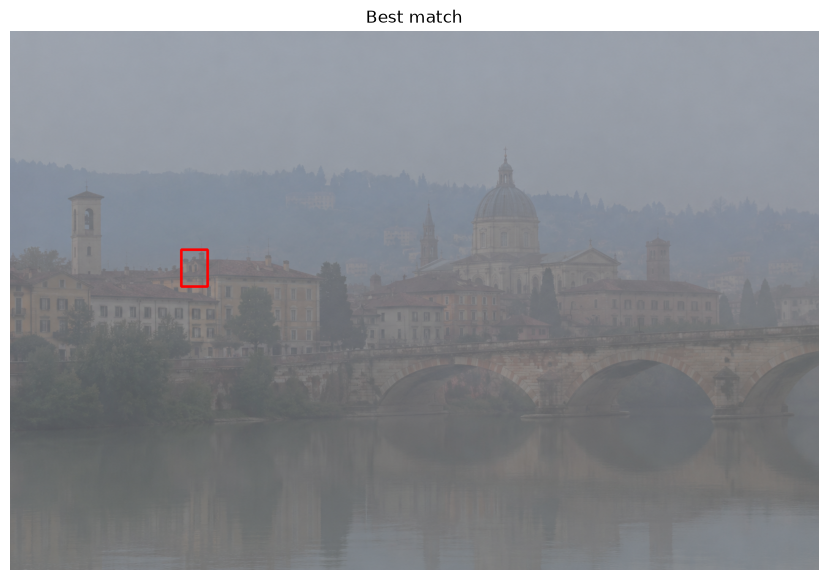

In [39]:
# Draw a rectangle around the best match
result = image_rgb.copy()


cv2.rectangle(
    result,
    (best_x, best_y),
    (best_x + patch_w, best_y + patch_h),
    (255, 0, 0),
    4
)

plt.figure(figsize=(12, 7))
plt.imshow(result)
plt.axis("off")
plt.title("Best match")
plt.show()


## Additional experiments
### - Visualize the N best matches
### - Change the descriptor of the patches to compute the normalization, e.g. using color histograms
### - Try with your own images